In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [5]:
df = pd.read_csv("pima_diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
#Case 1: Pandas
print(df.shape)
df.info()
display(df.describe().T)
df["Outcome"].value_counts()

(768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Outcome
0    500
1    268
Name: count, dtype: int64

In [9]:
#Case 2: Data cleaning (0 ko missing banao aur median se bharo)

cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zeros pehle:\n", (df[cols] == 0).sum())

df[cols] = df[cols].replace(0, np.nan)
df[cols] = df[cols].fillna(df[cols].median())

print("\nMissing ab:\n", df.isna().sum())

Zeros pehle:
 Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Missing ab:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [10]:
#Case 3: NumPy statistics

glucose = df["Glucose"].to_numpy()
print("Mean       :", np.mean(glucose).round(2))
print("Median     :", np.median(glucose))
print("Std dev    :", np.std(glucose).round(2))
print("Min / Max  :", glucose.min(), "/", glucose.max())
print("25/50/75 % :", np.percentile(glucose, [25, 50, 75]))
print("Glucose > 140 wale patients:", (glucose > 140).sum())

Mean       : 121.66
Median     : 117.0
Std dev    : 30.42
Min / Max  : 44.0 / 199.0
25/50/75 % : [ 99.75 117.   140.25]
Glucose > 140 wale patients: 192


In [11]:
#Case 4: NumPy se Z-score aur correlation
bmi = df["BMI"].to_numpy()
z = (bmi - bmi.mean()) / bmi.std()
print("Z-score mean ~", z.mean().round(4), " std ~", z.std().round(4))
print("Outliers (|z| > 3):", (np.abs(z) > 3).sum())

print("\nGlucose aur Outcome ka correlation:",
      np.corrcoef(df["Glucose"], df["Outcome"])[0, 1].round(3))

Z-score mean ~ 0.0  std ~ 1.0
Outliers (|z| > 3): 5

Glucose aur Outcome ka correlation: 0.493


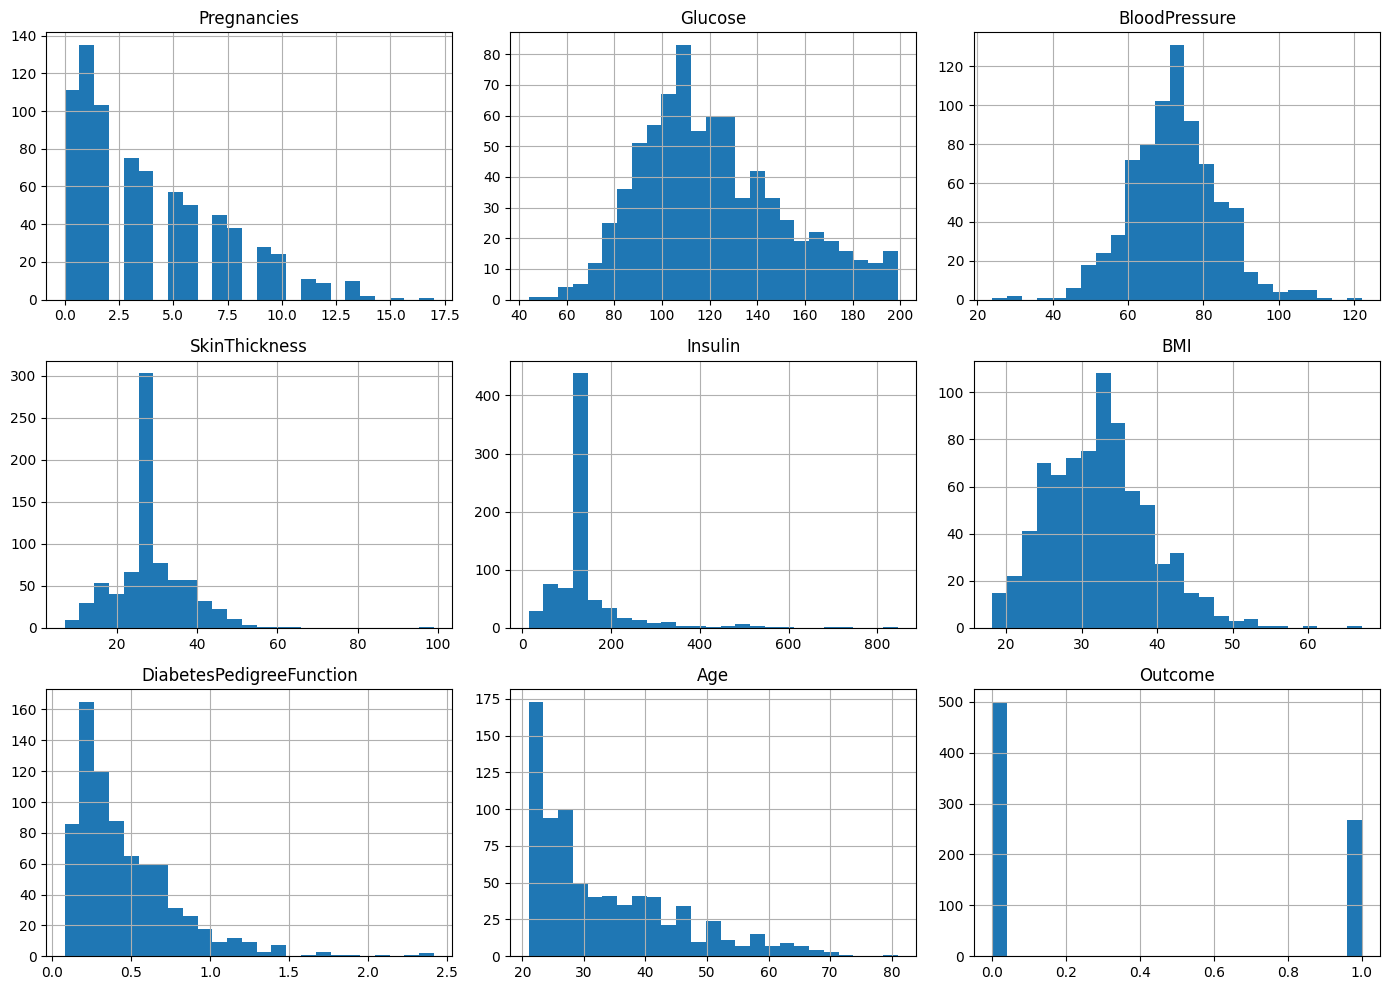

In [13]:
#Case 5: Histograms


df.hist(figsize=(14, 10), bins=25)
plt.tight_layout()
plt.show()#

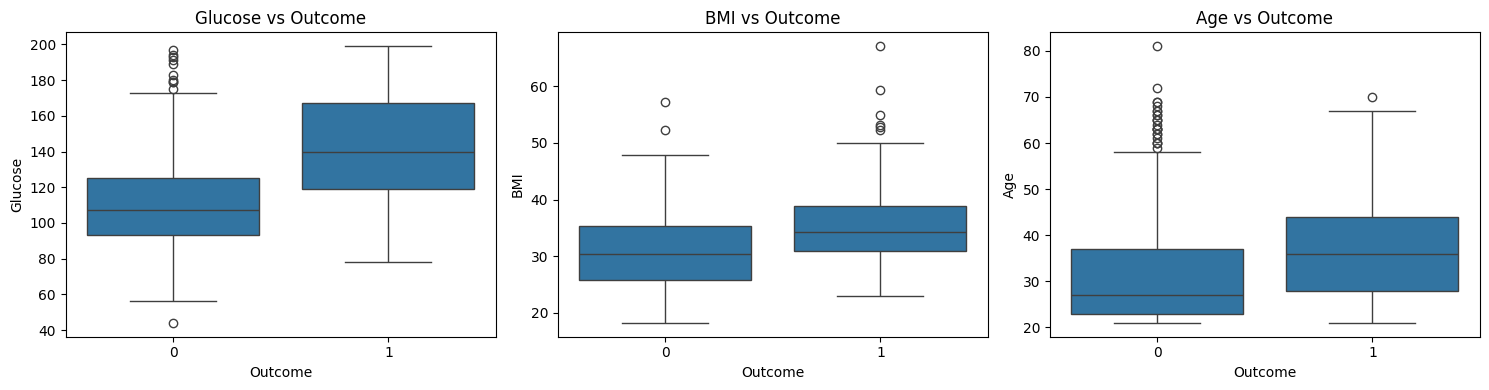

In [14]:
#Case 9: Boxplots

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["Glucose", "BMI", "Age"]):
    sns.boxplot(x="Outcome", y=c, data=df, ax=a)
    a.set_title(c + " vs Outcome")
plt.tight_layout()
plt.show()

In [16]:
# 7 chalao, phir Case 10

tmp = df.copy()
tmp["AgeGroup"] = pd.cut(tmp["Age"], [20, 30, 40, 50, 60, 100], labels=["21-30", "31-40", "41-50", "51-60", "60+"])
tmp["BMICat"] = pd.cut(tmp["BMI"], [0, 18.5, 25, 30, 100], labels=["Underweight", "Normal", "Overweight", "Obese"])

display(pd.crosstab(tmp["AgeGroup"], tmp["Outcome"], normalize="index").round(2))
display(pd.crosstab(tmp["BMICat"], tmp["Outcome"], normalize="index").round(2))

Outcome,0,1
AgeGroup,,
21-30,0.78,0.22
31-40,0.52,0.48
41-50,0.43,0.57
51-60,0.43,0.57
60+,0.74,0.26


Outcome,0,1
BMICat,,
Underweight,1.00,0.00
Normal,0.94,0.06
Overweight,0.76,0.24
Obese,0.54,0.46


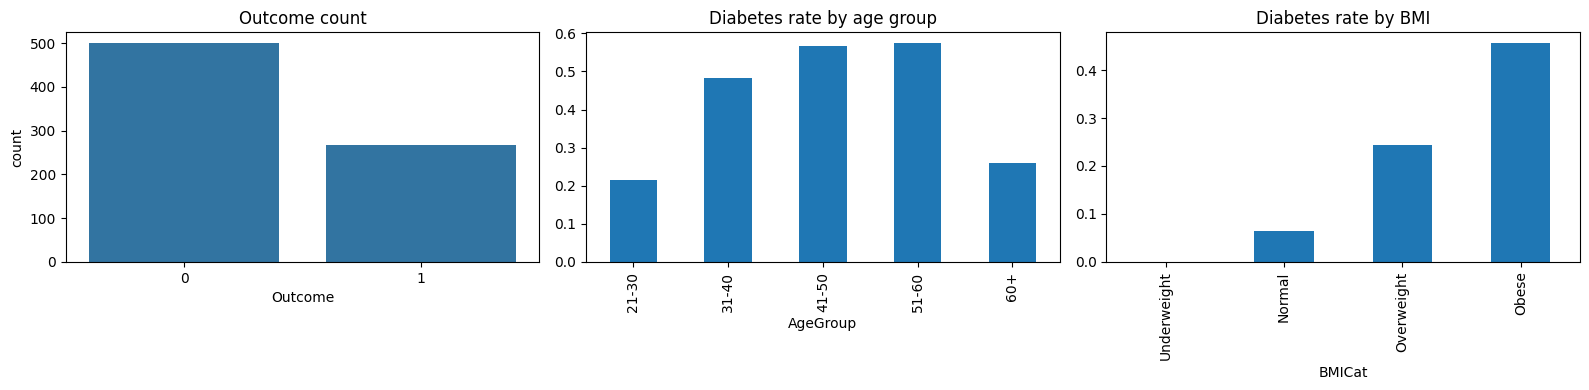

In [18]:
tmp = df.copy()
tmp["AgeGroup"] = pd.cut(tmp["Age"], [20, 30, 40, 50, 60, 100], labels=["21-30", "31-40", "41-50", "51-60", "60+"])
tmp["BMICat"] = pd.cut(tmp["BMI"], [0, 18.5, 25, 30, 100], labels=["Underweight", "Normal", "Overweight", "Obese"])

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="Outcome", data=df, ax=ax[0]); ax[0].set_title("Outcome count")
tmp.groupby("AgeGroup", observed=True)["Outcome"].mean().plot(kind="bar", ax=ax[1], title="Diabetes rate by age group")
tmp.groupby("BMICat", observed=True)["Outcome"].mean().plot(kind="bar", ax=ax[2], title="Diabetes rate by BMI")
plt.tight_layout()
plt.show()

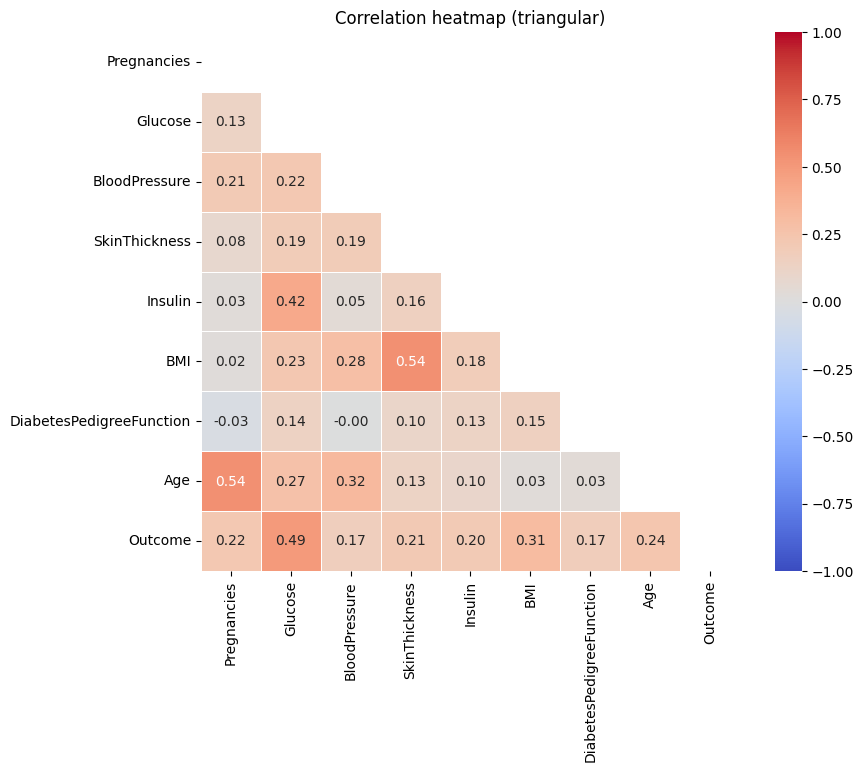

In [20]:
#Heatmaps

#Case: Triangular correlation heatmap (sirf neeche ka half)

corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5, square=True)
plt.title("Correlation heatmap (triangular)")
plt.show()

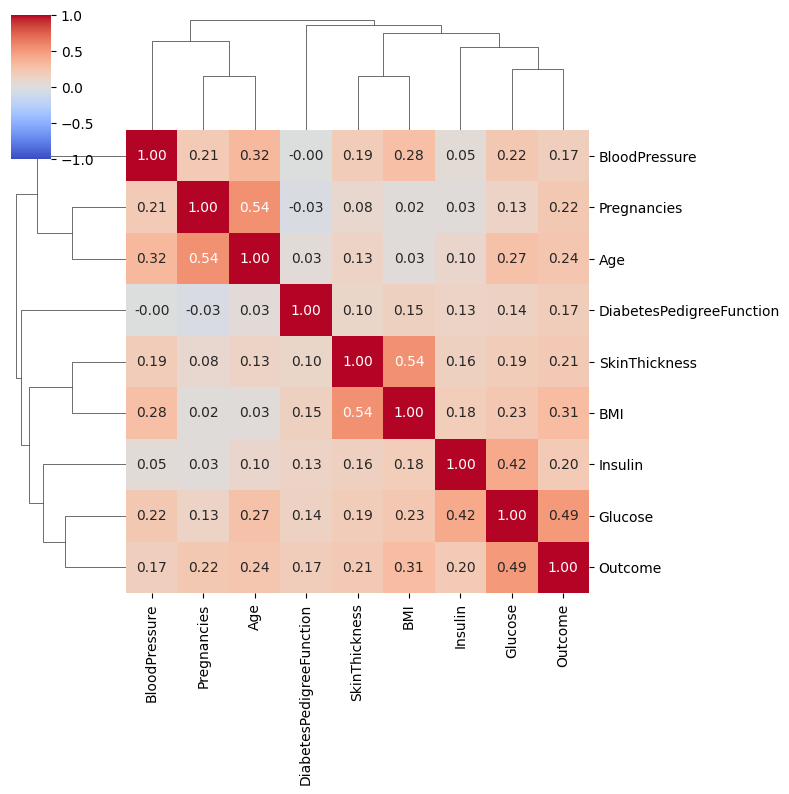

In [21]:
#Case 18: Clustermap (similar features ko group karke)

sns.clustermap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, figsize=(8, 8))
plt.show()

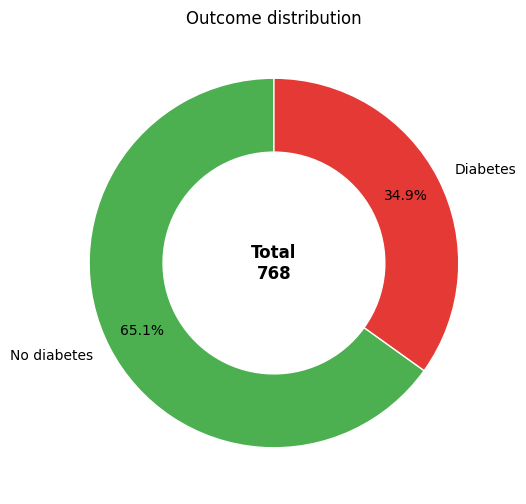

In [22]:
#Case 19: Outcome donut

def donut(values, labels, title, ax=None, colors=None):
    ax = ax or plt.gca()
    ax.pie(values, labels=labels, autopct="%1.1f%%", startangle=90, pctdistance=0.8,
           colors=colors, wedgeprops=dict(width=0.4, edgecolor="white"))
    ax.text(0, 0, f"Total\n{sum(values)}", ha="center", va="center", fontsize=12, fontweight="bold")
    ax.set_title(title)

counts = df["Outcome"].value_counts().sort_index()
plt.figure(figsize=(6, 6))
donut(counts.values, ["No diabetes", "Diabetes"], "Outcome distribution", colors=["#4CAF50", "#E53935"])
plt.show()

In [ ]:
tmp = df.copy()
tmp["AgeGroup"] = pd.cut(tmp["Age"], [20, 30, 40, 50, 60, 100], labels=["21-30", "31-40", "41-50", "51-60", "60+"])
tmp["BMICat"] = pd.cut(tmp["BMI"], [0, 18.5, 25, 30, 100], labels=["Underweight", "Normal", "Overweight", "Obese"])
tmp["Result"] = tmp["Outcome"].map({0: "No diabetes", 1: "Diabetes"})
colors = {"No diabetes": "#4CAF50", "Diabetes": "#E53935"}
sns.set_theme(style="whitegrid")